In [21]:
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder,get_acronym

eps = 1E-7
rcpsize = 15
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['o','s','h','^','*']
_linestyles = ['-','--','dotted']
plot_id = 0

depths = {"deepseek":61,
          "llama":32}

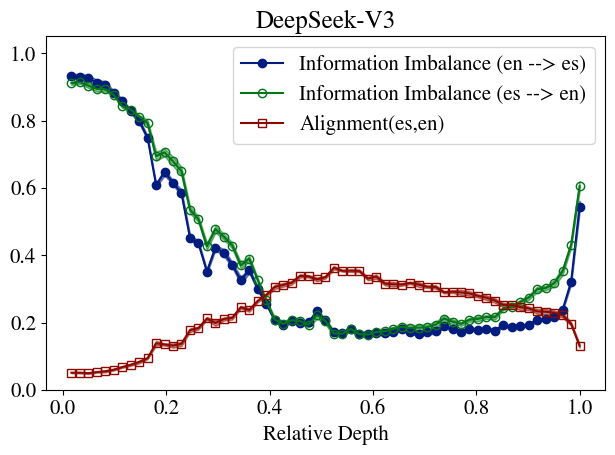

In [25]:
models = [
          'deepseek',
          # 'llama',
          ]
mask = 2
language_pairs = [('english','spanish'),
                  # ('english','italian'),
                  # ('spanish','italian'),
                  # ('german','hungarian'),
                  ]
n_files = 500

figsfolder = makefolder(base=f'./results/figs/translations/',
                        create_folder=True,
                        n_files=n_files,
                        )

batch_size = 10 
Ns = batch_size*n_files

n_tokens_list = [20]

fig,ax = plt.subplots(1,1,
                            # figsize=(8,6),
                            # constrained_layout=True,
                            )

k_list = [10]
min_token_length = 40

seed_list = [0,1,2,3,4]
batch_shuffle = 0
avg = 0

for k_id,k in enumerate(k_list):
    for n_tokens_id,n_tokens in enumerate(n_tokens_list):
      for model_id,model in enumerate(models):
        _model = 'DeepSeek-V3' if model == 'deepseek' else 'LLama3.1-8b'
        for language_pair_id, language_pair in enumerate(language_pairs):
          (languageA,languageB) = language_pair
          IIs = np.zeros(shape=(len(seed_list),2,depths[model]))
          A = np.zeros(shape=(len(seed_list),depths[model]))
          for seed_id, seed in enumerate(seed_list):
            II_folder = makefolder(base=f'./results/santiago/',
                                  batch_shuffle=batch_shuffle,
                                  modelA=model,
                                  modelB=model,
                                  n_files=n_files,
                                  min_token_length=min_token_length,
                                  languageA=languageA,
                                  languageB=languageB,
                                  mask=mask,
                                  k=k,
                                  Nbits=Nbits,
                                  seed=seed,
                                  )
            A[seed_id,:] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{1}_alignment.npy').diagonal()
            IIs[seed_id,0,:] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg}_AB.npy').diagonal()
            IIs[seed_id,1,:] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg}_BA.npy').diagonal()
          A_layer_ids = np.arange(1,depths[model]+1)

          ax.plot(A_layer_ids/depths[model],
                  IIs[:,0,:].mean(axis=0),
                  # label=f'{get_acronym(languageA)}] --> {get_acronym(languageB)}]',
                  linestyle=_linestyles[model_id],
                  color=colors[0],
                  marker=markers[avg],
                  markerfacecolor=colors[0],   # Open (hollow) circle
                  markeredgecolor=colors[0],# Outline color same as line
                  label = f'Information Imbalance ({get_acronym(languageA)} --> {get_acronym(languageB)})',
                  )
          ax.fill_between(A_layer_ids/depths[model],
                  IIs[:,0,:].mean(axis=0)-IIs[:,0,:].std(axis=0),
                  IIs[:,0,:].mean(axis=0)+IIs[:,0,:].std(axis=0),
                  alpha=0.5,
                  linestyle=_linestyles[model_id],
                  color=colors[0],
                  )
          ax.plot(A_layer_ids/depths[model],
                  IIs[:,1,:].mean(axis=0),
                  color=colors[1],
                  label=f'Information Imbalance ({get_acronym(languageB)} --> {get_acronym(languageA)})',
                  marker=markers[avg],
                  markerfacecolor='none',   # Open (hollow) circle
                  markeredgecolor=colors[1],# Outline color same as line
                  # label = f' {get_acronym(languageB)} --> {get_acronym(languageA)}',
                  )
          ax.fill_between(A_layer_ids/depths[model],
                  IIs[:,1,:].mean(axis=0)-IIs[:,1,:].std(axis=0),
                  IIs[:,1,:].mean(axis=0)+IIs[:,1,:].std(axis=0),
                  alpha=0.5,
                  color=colors[1],
                  )
          ax.plot(A_layer_ids/depths[model],
                  A.mean(axis=0),
                  label=f'Alignment({get_acronym(languageB)},{get_acronym(languageA)})',
                  color=colors[2],
                  marker=markers[1],
                  markerfacecolor='none',   # Open (hollow) circle
                  )
          ax.fill_between(A_layer_ids/depths[model],
                  A[:,:].mean(axis=0)-A[:,:].std(axis=0),
                  A[:,:].mean(axis=0)+A[:,:].std(axis=0),
                  alpha=0.5,
                  color=colors[2],
                  )

ax.set_xlabel('Relative Depth')
# ax.set_ylabel('Information Imbalance')
ax.set_ylim(0,1.05)
ax.legend(loc='upper right')
ax.set_title(f'{_model}')
fig.savefig(f'{figsfolder}alignment_comparison{n_tokens}.pdf',
              bbox_inches='tight',
)